In [5]:
from pathlib import Path
import pandas as pd

# Load processed global ads dataset
candidates = [
    Path("data/processed/global_ads_performance_dataset_processed.csv"),
    Path("../data/processed/global_ads_performance_dataset_processed.csv"),
]

csv_path = next((p for p in candidates if p.exists()), None)
if csv_path is None:
    raise FileNotFoundError(
        "Could not find processed CSV. Tried: " + ", ".join(str(p) for p in candidates)
    )

df = pd.read_csv(csv_path)
print("Loaded from:", csv_path.resolve())
print("Shape:", df.shape)

# Show all unique industries
unique_industries = sorted(
    df["industry"].dropna().astype(str).str.strip().unique().tolist()
)
print("\nUnique industries:")
for industry in unique_industries:
    print(f"- {industry}")

Loaded from: /Users/Carys/Documents/Github/ads-analysis/data/processed/global_ads_performance_dataset_processed.csv
Shape: (1800, 14)

Unique industries:
- E-commerce
- EdTech
- Fintech
- Healthcare
- SaaS


In [6]:
# Best ROAS campaign type for each platform + industry combination
# ROAS formula used here: total_revenue / total_ad_spend
roas_by_platform_industry_campaign = (
    df.groupby(["platform", "industry", "campaign_type"], as_index=False)
      .agg(
          total_revenue=("revenue", "sum"),
          total_ad_spend=("ad_spend", "sum"),
          observations=("ROAS", "size"),
          mean_row_roas=("ROAS", "mean"),
      )
)

roas_by_platform_industry_campaign["group_roas"] = (
    roas_by_platform_industry_campaign["total_revenue"]
    / roas_by_platform_industry_campaign["total_ad_spend"]
)

best_roas_by_platform_industry = (
    roas_by_platform_industry_campaign
    .sort_values(["platform", "industry", "group_roas"], ascending=[True, True, False])
    .groupby(["platform", "industry"], as_index=False)
    .first()
    .rename(columns={
        "campaign_type": "best_campaign_type",
        "group_roas": "best_group_roas",
    })
    .sort_values(["platform", "best_group_roas"], ascending=[True, False])
)

print("ROAS method: group_roas = sum(revenue) / sum(ad_spend) for each platform-industry-campaign group")
print("Best campaign type by platform and industry:")
display(
    best_roas_by_platform_industry[[
        "platform",
        "industry",
        "best_campaign_type",
        "best_group_roas",
        "total_revenue",
        "total_ad_spend",
        "observations",
    ]]
)

_processed_out = Path("data/processed")
if not _processed_out.exists():
    _processed_out = Path("../data/processed")
_roas_csv = _processed_out / "best_roas_by_platform_industry.csv"
best_roas_by_platform_industry.to_csv(_roas_csv, index=False)
print(f"Saved best ROAS by platform/industry: {_roas_csv.resolve()}")


ROAS method: group_roas = sum(revenue) / sum(ad_spend) for each platform-industry-campaign group
Best campaign type by platform and industry:


,platform,industry,best_campaign_type,best_group_roas,total_revenue,total_ad_spend,observations
1,Google Ads,EdTech,Video,4.459468,1540081.32,345350.93,37
0,Google Ads,E-commerce,Search,4.275280,1324398.95,309780.63,37
4,Google Ads,SaaS,Search,4.150986,1367054.35,329332.44,37
2,Google Ads,Fintech,Display,3.901505,1036824.53,265749.86,33
3,Google Ads,Healthcare,Video,3.715438,1011023.92,272114.34,27
9,Meta Ads,SaaS,Search,8.021125,465032.02,57975.91,17
8,Meta Ads,Healthcare,Shopping,7.713885,878824.94,113927.67,39
6,Meta Ads,EdTech,Display,6.796471,749331.20,110252.98,34
5,Meta Ads,E-commerce,Video,5.704112,665418.01,116655.85,37
7,Meta Ads,Fintech,Display,5.559777,583458.66,104942.82,25


In [8]:
# Highest pooled ROAS for a single (industry, campaign_type) on each platform
# Uses same group_roas as cell above: sum(revenue) / sum(ad_spend) per group
best_one_per_platform = (
    roas_by_platform_industry_campaign.sort_values(
        ["platform", "group_roas"], ascending=[True, False]
    )
    .groupby("platform", as_index=False)
    .first()
    .rename(
        columns={
            "industry": "best_industry",
            "campaign_type": "best_campaign_type",
            "group_roas": "best_group_roas",
        }
    )
)

print("Best single industry + campaign type per platform (max group_roas):")
display(
    best_one_per_platform[
        [
            "platform",
            "best_industry",
            "best_campaign_type",
            "best_group_roas",
            "total_revenue",
            "total_ad_spend",
            "observations",
        ]
    ].round(3)
)

_processed_out = Path("data/processed")
if not _processed_out.exists():
    _processed_out = Path("../data/processed")
_max_csv = _processed_out / "max_group_roas_per_platform.csv"
best_one_per_platform.to_csv(_max_csv, index=False)
print(f"Saved max group ROAS per platform: {_max_csv.resolve()}")



Best single industry + campaign type per platform (max group_roas):


,platform,best_industry,best_campaign_type,best_group_roas,total_revenue,total_ad_spend,observations
0,Google Ads,EdTech,Video,4.459,1540081.32,345350.93,37
1,Meta Ads,SaaS,Search,8.021,465032.02,57975.91,17
2,TikTok Ads,E-commerce,Search,10.700,1489578.34,139206.94,24


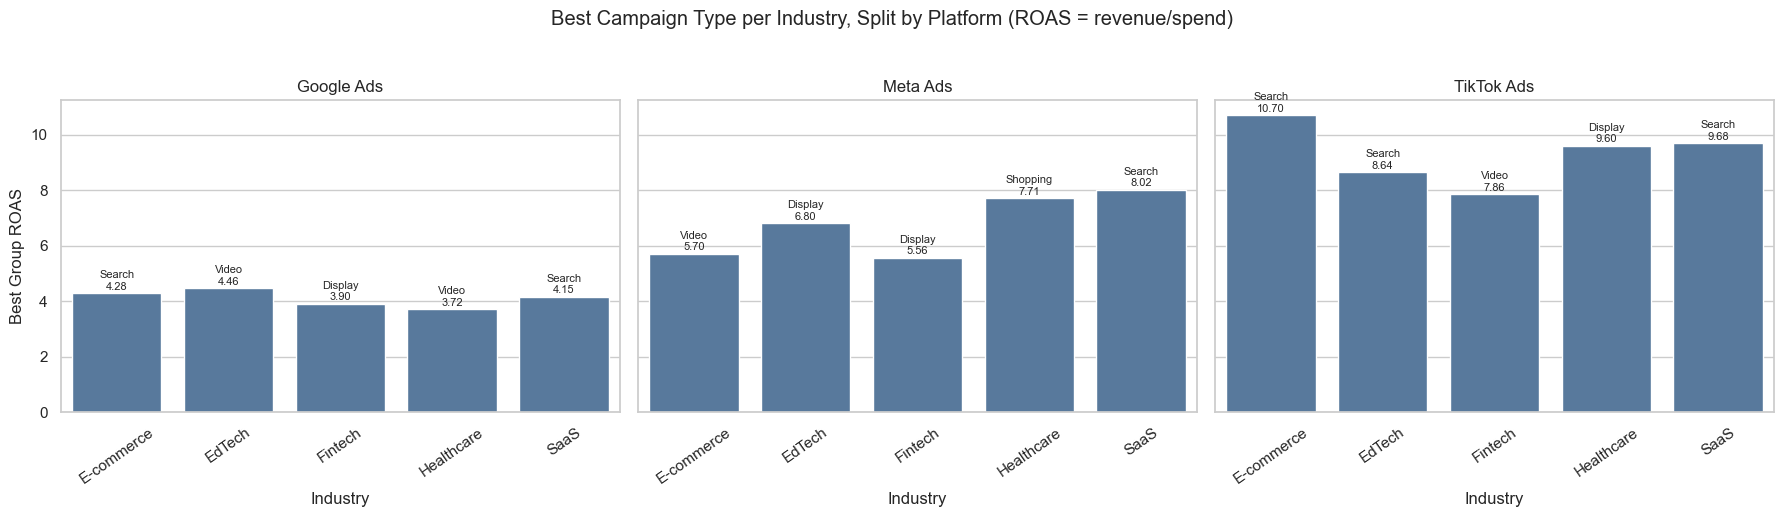

In [7]:
# Visualization: one panel per platform, with winning campaign type labels
import matplotlib.pyplot as plt
import seaborn as sns

viz_df = best_roas_by_platform_industry.copy()
platform_order = ["Google Ads", "Meta Ads", "TikTok Ads"]
industry_order = sorted(viz_df["industry"].unique())

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, platform in zip(axes, platform_order):
    subset = viz_df[viz_df["platform"] == platform].copy()
    subset["industry"] = pd.Categorical(subset["industry"], categories=industry_order, ordered=True)
    subset = subset.sort_values("industry")

    sns.barplot(
        data=subset,
        x="industry",
        y="best_group_roas",
        ax=ax,
        color="#4C78A8",
    )

    ax.set_title(platform)
    ax.set_xlabel("Industry")
    ax.set_ylabel("Best Group ROAS" if platform == "Google Ads" else "")
    ax.tick_params(axis="x", rotation=35)

    # Label each bar with campaign type and ROAS value for clarity
    for i, row in enumerate(subset.itertuples(index=False)):
        ax.text(
            i,
            row.best_group_roas + 0.05,
            f"{row.best_campaign_type}\n{row.best_group_roas:.2f}",
            ha="center",
            va="bottom",
            fontsize=8,
        )

fig.suptitle("Best Campaign Type per Industry, Split by Platform (ROAS = revenue/spend)", y=1.03)
plt.tight_layout()
plt.show()